# Exploratory Data Analysis (EDA)

## Bank Marketing Dataset

This notebook explores the Bank Marketing dataset from the UCI Machine Learning Repository.

**Goal:** Understand the dataset, identify data quality issues, and investigate patterns relevant to predicting term deposit subscriptions.

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Load the Bank Marketing dataset
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45211, 16)
Target shape: (45211, 1)


In [2]:
 X.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


## Target Variable Analysis

Analyze the distribution of the target variable to identify potential class imbalance.

In [3]:
# Count the number of observations in each class
y.iloc[:, 0].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [4]:
# Percentage distribution of the target variable
y.iloc[:, 0].value_counts(normalize=True).mul(100).round(2)

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

**Observation:** The target variable is imbalanced, with approximately 88.3% of observations belonging to the negative class and 11.7% to the positive class.

Therefore, accuracy alone may be misleading. Additional evaluation metrics, particularly Precision, Recall, F1-score, and PR-AUC, should be considered when evaluating classification models.

## Feature Analysis

Explore feature types, missing values, and data quality.

In [5]:
# Inspect dataset structure and data types
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
dtypes: int64(7), str(9)
memory usage: 5.5 MB


In [6]:
# Count missing values per feature
X.isna().sum().sort_values(ascending=False)

poutcome       36959
contact        13020
education       1857
job              288
default            0
balance            0
age                0
marital            0
loan               0
housing            0
month              0
day_of_week        0
duration           0
campaign           0
pdays              0
previous           0
dtype: int64

### Investigating Missing Values

Examine missing values in categorical features before deciding how to handle them.

In [7]:
# Distribution of previous campaign outcomes
X["poutcome"].value_counts(dropna=False)

poutcome
NaN        36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

In [8]:
# Check whether missing outcomes are related to previous contacts
pd.crosstab(
    X["previous"] == 0,
    X["poutcome"].isna()
)

poutcome,False,True
previous,,
False,8252,5
True,0,36954


**Observation:** Most missing values in `poutcome` (36,954 out of 36,959)
correspond to customers with no previous contacts.

Only 5 records have previous contacts but a missing outcome.

**Decision:** Preserve this feature and distinguish between customers
with no previous contacts and customers with an unknown previous outcome
during preprocessing.

In [9]:
# Inspect missing outcomes despite previous contacts
X.loc[
    (X["previous"] > 0) & X["poutcome"].isna(),
    ["previous", "poutcome"]
]

,previous,poutcome
40658,1,NaN
41821,5,NaN
42042,2,NaN
43978,2,NaN
45021,7,NaN


In [10]:
# Distribution of contact types, including missing values
X["contact"].value_counts(dropna=False)

contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

In [11]:
# Distribution of contact types, including missing values
X["contact"].value_counts(dropna=False)

contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

In [12]:
# Distribution of education levels
X["education"].value_counts(dropna=False)

education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

In [13]:
# Distribution of job categories
X["job"].value_counts(dropna=False)

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64

**Missing Values — Conclusions**

Four categorical features contain missing values: `poutcome`, `contact`, `education`, and `job`.

Missing values will be preserved during EDA. During preprocessing, unknown categories will be handled explicitly, while `poutcome` will distinguish between customers with no previous contacts and those with an unknown previous outcome.

No observations will be removed solely because of these missing values.

## Numerical Features Analysis

Explore descriptive statistics and identify potential outliers or unusual values.

In [14]:
# Summary statistics for numerical features
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [15]:
# Count records with no previous contact
(X["pdays"] == -1).value_counts()

pdays
True     36954
False     8257
Name: count, dtype: int64

In [16]:
# Check the relationship between pdays and previous contacts
pd.crosstab(
    X["previous"] == 0,
    X["pdays"] == -1
)

pdays,False,True
previous,,
False,8257,0
True,0,36954


**Observation — `pdays`:**

The value `-1` indicates that no previous contact was recorded.

All 36,954 observations with `previous = 0` have `pdays = -1`, while all observations with previous contacts have a different `pdays` value.

**Decision:** Treat `-1` as a special value during preprocessing rather than interpreting it as a regular number of days.

### Numerical Feature Distributions

Visualize numerical features to understand their distributions,
skewness, and potential outliers.

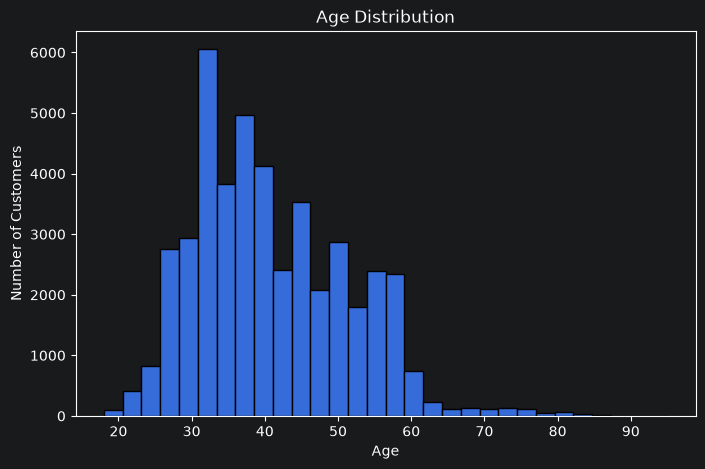

In [17]:
import matplotlib.pyplot as plt

# Age distribution
plt.figure(figsize=(8, 5))

plt.hist(X["age"], bins=30, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

**Observation — Age Distribution**

Most customers are between 30 and 60 years old, with a higher concentration around ages 30–40.

The distribution is slightly right-skewed, with relatively few customers above 60.

Older customers may represent unusual observations, but there is no immediate evidence that these values are invalid.

Further analysis is needed to determine whether age is associated with term deposit subscriptions.

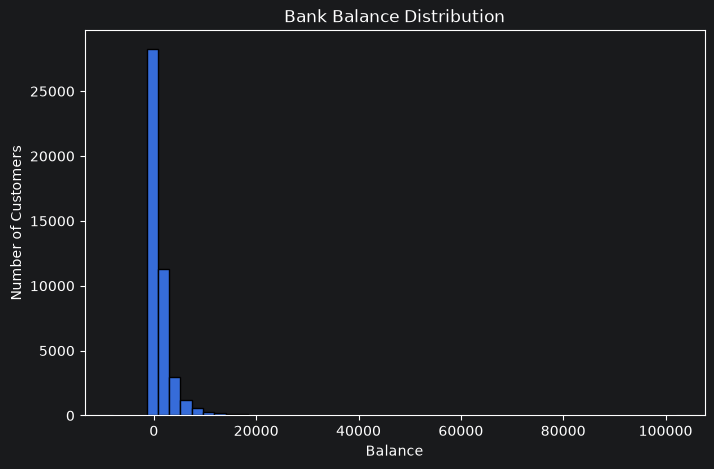

In [18]:
# Balance distribution
plt.figure(figsize=(8, 5))

plt.hist(X["balance"], bins=50, edgecolor="black")

plt.title("Bank Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Number of Customers")

plt.show()

1st percentile: -627.0
99th percentile: 13164.900000000001


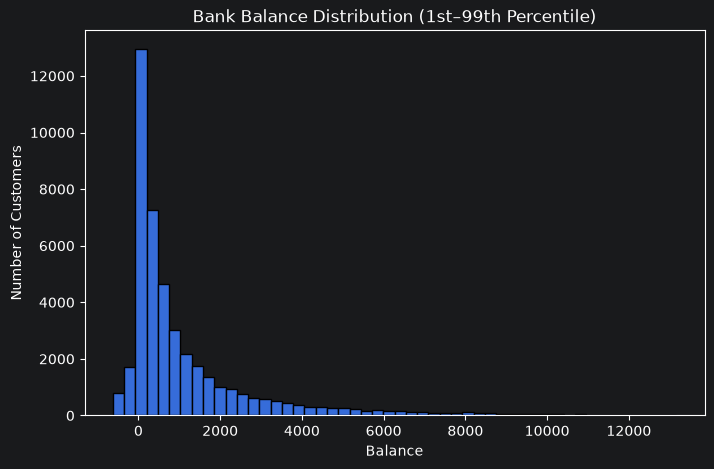

In [19]:
# Calculate the 1st and 99th percentiles
lower = X["balance"].quantile(0.01)
upper = X["balance"].quantile(0.99)

print("1st percentile:", lower)
print("99th percentile:", upper)

# Select central 98% for visualization only
balance_central = X.loc[
    X["balance"].between(lower, upper),
    "balance"
]

plt.figure(figsize=(8, 5))

plt.hist(balance_central, bins=50, edgecolor="black")

plt.title("Bank Balance Distribution (1st–99th Percentile)")
plt.xlabel("Balance")
plt.ylabel("Number of Customers")

plt.show()

**Observation — Bank Balance Distribution**

The `balance` feature is strongly right-skewed, with most customers having relatively low balances and a small number of customers having exceptionally high balances.

The mean (1,362) is substantially higher than the median (448), indicating the influence of large values.

Extreme values make the full distribution difficult to visualize. Therefore, a percentile-based visualization is used to better understand the central distribution without modifying the original dataset.

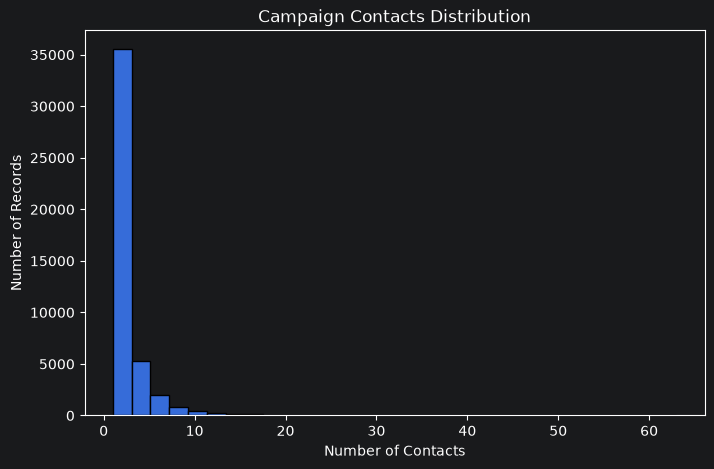

In [20]:
# Campaign contacts distribution
plt.figure(figsize=(8, 5))

plt.hist(X["campaign"], bins=30, edgecolor="black")

plt.title("Campaign Contacts Distribution")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Records")

plt.show()

In [21]:
# Number of records by contact count
X["campaign"].value_counts().sort_index().head(10)

campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
Name: count, dtype: int64

In [22]:
# Percentage of records with 1 to 3 contacts
print(f"1–3 contacts: {(X['campaign'] <= 3).mean():.2%}")

# Percentage of records with 10 or more contacts
print(f"10+ contacts: {(X['campaign'] >= 10).mean():.2%}")

1–3 contacts: 78.68%
10+ contacts: 3.23%


**Observation — Campaign Contacts**

The `campaign` feature is strongly right-skewed, with 78.68% of observations having between 1 and 3 contacts.

Only 3.23% of observations have 10 or more contacts, although the maximum recorded value is 63.

High contact counts may represent unusual observations, but they are not necessarily errors.

**Data leakage consideration:** Since `campaign` includes contacts made during the current campaign, its availability at prediction time must be considered. For a model predicting outcomes before the first contact, this feature should be excluded.

## Feature Relationships with Target

Explore how customer characteristics are associated with term deposit subscriptions.

In [23]:
# Subscription rate by education level
education_rates = pd.crosstab(
    X["education"].fillna("unknown"),
    y.iloc[:, 0],
    normalize="index"
).mul(100).round(2)

education_rates

y,no,yes
education,,
primary,91.37,8.63
secondary,89.44,10.56
tertiary,84.99,15.01
unknown,86.43,13.57


**Observation — Education vs. Subscription**

Subscription rates vary across education levels:

- Tertiary education: 15.01%
- Secondary education: 10.56%
- Primary education: 8.63%
- Unknown education: 13.57%

Customers with tertiary education have the highest subscription rate among these groups.

This suggests that education may be a useful predictive feature. However, the observed association does not imply causation.

In [27]:
# Subscription rate by job category
job_rates = pd.crosstab(
    X["job"].fillna("unknown"),
    y.iloc[:, 0],
    normalize="index"
)["yes"].mul(100).round(2)

# Number of records per job category
job_counts = X["job"].fillna("unknown").value_counts()

# Combine counts and subscription rates
job_summary = pd.DataFrame({
    "count": job_counts,
    "subscription_rate (%)": job_rates
}).sort_values("subscription_rate (%)", ascending=False)

job_summary

,count,subscription_rate (%)
job,,
student,938,28.68
retired,2264,22.79
unemployed,1303,15.50
management,9458,13.76
admin.,5171,12.20
self-employed,1579,11.84
unknown,288,11.81
technician,7597,11.06
services,4154,8.88


**Observation — Job vs. Subscription**

Subscription rates vary considerably across job categories.

Students (28.68%) and retired customers (22.79%) have the highest observed subscription rates, both exceeding the overall subscription rate of approximately 11.7%.

These groups contain 938 and 2,264 observations, respectively, providing meaningful sample sizes for an initial exploratory comparison.

However, subscription rates should be considered alongside group sizes, and these associations do not establish causation.

**Conclusion:** Job category may provide useful predictive information and should be considered during model development.